### Permutations

Given an array nums of distinct integers, return all the possible permutations. You can return the answer in any order.

 

Example 1:

Input: nums = [1,2,3]
Output: [[1,2,3],[1,3,2],[2,1,3],[2,3,1],[3,1,2],[3,2,1]]
Example 2:

Input: nums = [0,1]
Output: [[0,1],[1,0]]
Example 3:

Input: nums = [1]
Output: [[1]]
 

In [2]:
from typing import List

In [4]:
class Solution:
    def permute(self, nums: list[int]) -> list[list[int]]:

        permutations = []

        # we define a dfs function
        # according to our stace space tree, we need to include an index, then we need to recursively call dfs again
        # keep calling until we get path == nums length, but make sure we do not use the already included index

        def dfs(used_indices, path):

            # we can store path to output once path len == nums len
            # BASE CASE
            if len(path) == len(nums):
                permutations.append(path.copy())
                return

            # we traverse through each element of nums
            for i in range(0, len(nums)):

                # if index is already included, we continue, this is to prevent same number from being selected again
                if i in used_indices:
                    continue

                # CHOOSE: add it to the path and then add index to used_indices set
                path.append(nums[i])
                used_indices.add(i)

                # EXPLORE: call dfs function again, so we can explore other elements within the array
                dfs(used_indices, path)
                

                # UNDO: once this dfs function returns control, we simply pop the appended element from the path, remove it from used_indices set as well
                path.pop()
                used_indices.remove(i)

        used = set()
        dfs(used, [])
        return permutations
        

Each copy takes \(O(n)\) time.

Thus:
\[
\boxed{O(n \cdot n!)}
\]

This bound also includes the cost of scanning indices and exploring the recursion tree.
Auxiliary space complexity: \(O(n)\)
Component	Maximum space
Recursion stack	\(O(n)\)
Current path	\(O(n)\)
used_indices set	\(O(n)\)

Therefore:
\[
\boxed{O(n)}
\]

This excludes the output.
Total space including output: \(O(n \cdot n!)\)
There are \(n!\) permutations, each containing \(n\) elements.
\[
\boxed{O(n \cdot n!)}
\]


4. Your reusable backtracking patterns
You now have two important patterns you can apply to future problems.
	LC 78 — Subsets	LC 46 — Permutations
Main state	start_index, path	used_indices, path
Loop	From start_index onward	Across all indices
Valid choice	Any remaining later index	Any unused index
Recursive call	dfs(i + 1, path)	dfs(used_indices, path)
Save result	Every DFS call	When path length equals n
Time	\(O(n2^n)\)	\(O(n \cdot n!)\)
Auxiliary space	\(O(n)\)	\(O(n)\)

### Backtracking without using for loop

In [5]:
class Solution:
    def permute(self, nums: list[int]) -> list[list[int]]:

        permutations = []
        used = set()

        def dfs(index, path):

            # base case, when do we add a path to the output
            if len(path) == len(nums):
                permutations.append(path.copy())
                return

            # base case, when do we stop the recursion
            if index == len(nums):
                return

            # when do we skip index
            if index in used:
                dfs(index+1)
                return


            # CHOICE 1: we skip the current element
            dfs(index+1, path)

            # CHOICE 2: we append the current element to the path and include it
            path.append(nums[index])
            used.add(index)

            # EXPLORE all the next elements for the path starting from index 0
            dfs(0)

            #UNDO
            path.pop()
            used.remove(index)

        dfs(0, [])
        return permutations

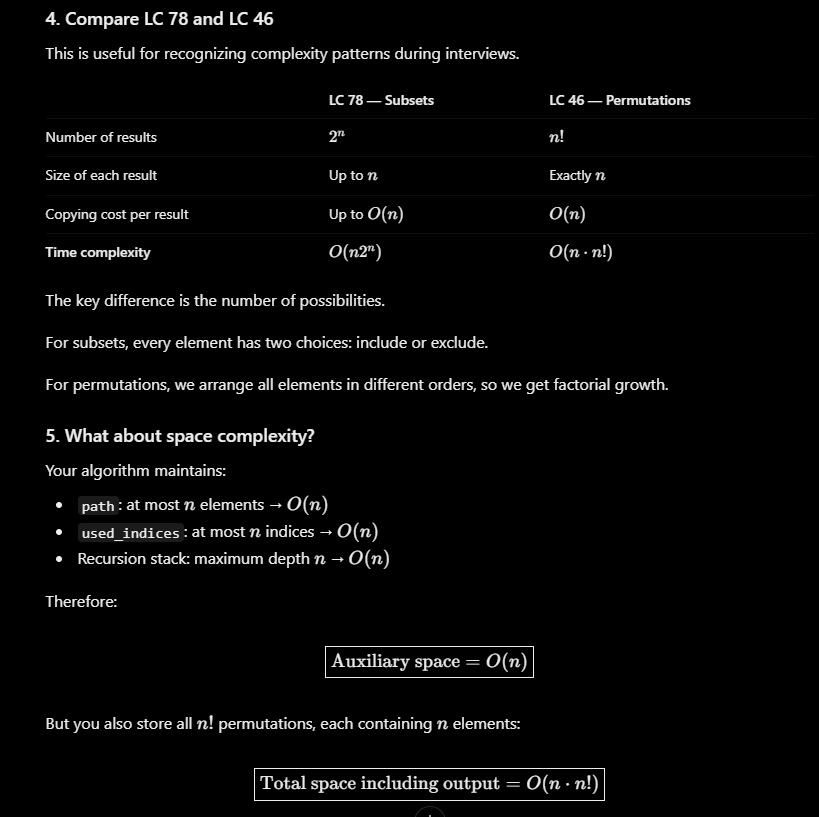